# Logistic Regression — Intuition + Visualization

This notebook explains Logistic Regression with math intuition, plots, and simple animations.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

## Sigmoid Function

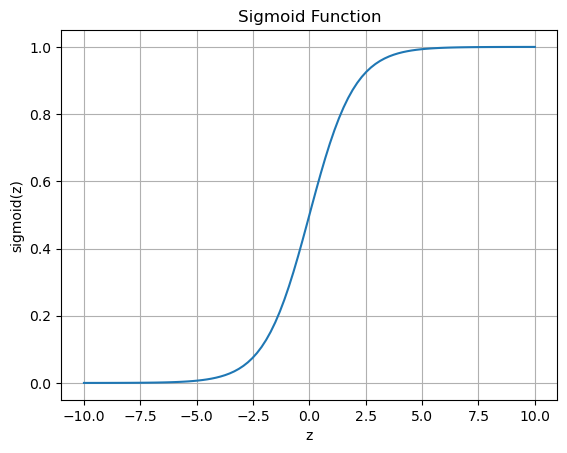

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-10, 10, 100)
plt.plot(z, sigmoid(z))
plt.title('Sigmoid Function')
plt.xlabel('z')
plt.ylabel('sigmoid(z)')
plt.grid()
plt.show()

## Generate Sample Data

In [3]:
np.random.seed(0)
X = np.random.randn(100, 1)
y = (X > 0).astype(int)

## Logistic Regression Training (Gradient Descent)

In [4]:
w = 0
b = 0
lr = 0.1
epochs = 50

losses = []

for epoch in range(epochs):
    z = w * X + b
    y_pred = sigmoid(z)
    
    loss = -np.mean(y*np.log(y_pred + 1e-9) + (1-y)*np.log(1-y_pred + 1e-9))
    losses.append(loss)
    
    dw = np.mean((y_pred - y) * X)
    db = np.mean(y_pred - y)
    
    w -= lr * dw
    b -= lr * db

print('Final w:', w, 'b:', b)

Final w: 1.2458255442447788 b: 0.12538044238173518


## Loss Curve

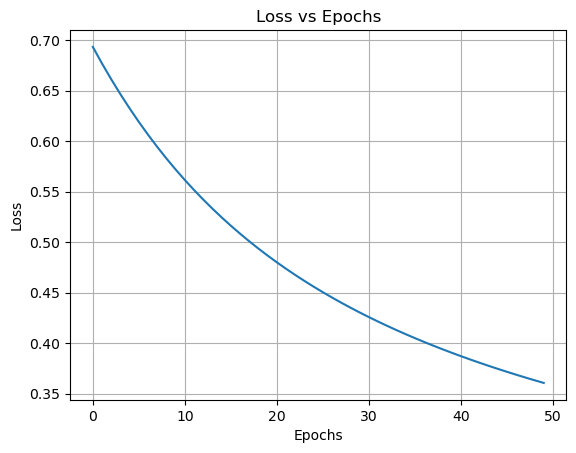

In [5]:
plt.plot(losses)
plt.title('Loss vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid()
plt.show()

## Decision Boundary Visualization

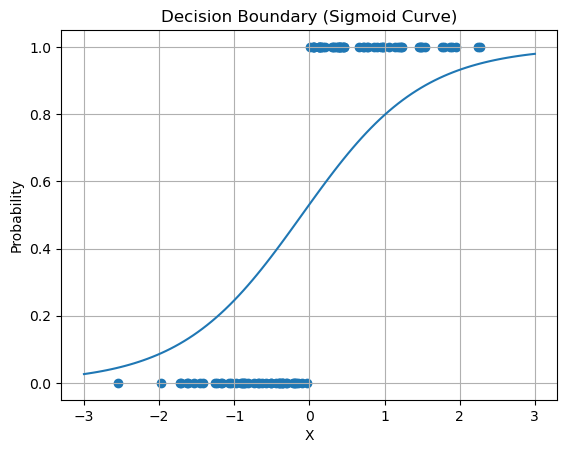

In [6]:
plt.scatter(X, y)

x_vals = np.linspace(-3, 3, 100)
y_vals = sigmoid(w * x_vals + b)

plt.plot(x_vals, y_vals)
plt.title('Decision Boundary (Sigmoid Curve)')
plt.xlabel('X')
plt.ylabel('Probability')
plt.grid()
plt.show()

## Animation of Learning

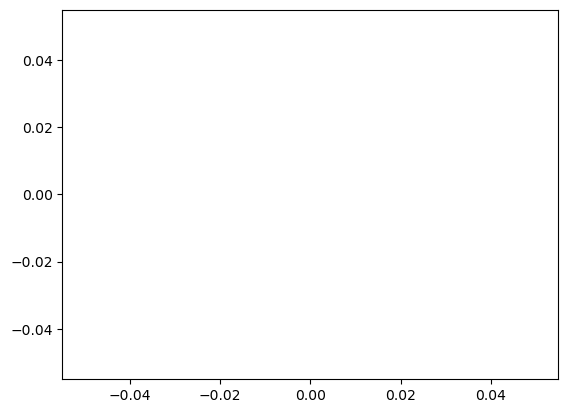

In [7]:
fig, ax = plt.subplots()
line, = ax.plot([], [])

def update(epoch):
    global w, b
    z = w * X + b
    y_pred = sigmoid(z)
    
    dw = np.mean((y_pred - y) * X)
    db = np.mean(y_pred - y)
    
    w -= lr * dw
    b -= lr * db
    
    x_vals = np.linspace(-3, 3, 100)
    y_vals = sigmoid(w * x_vals + b)
    
    line.set_data(x_vals, y_vals)
    ax.set_xlim(-3, 3)
    ax.set_ylim(0, 1)
    return line,

ani = FuncAnimation(fig, update, frames=30)
plt.show()